In [1]:
import marimo as mo

# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

In [2]:
NAMES = "group11-section1"

## 0. Overall Instructions

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks.

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

### Descriptive Analysis
We compute summary statistics for each feature, checking the mean, standard deviation, min, max, and percentiles to check for extreme values or skewness. We plot histograms to inspect each distribution, and we compute Pearson correlation coefficients alongside scatter plots of each ingredient and age against compressive strength. This lets us see whether relationships appear monotonic, linear, or curved.

### Data Preprocessing
The input features operate on very different measurement units and ranges, with aggregate quantities exceeding 1000 kg/m^3 while superplasticizer values are often below 10 kg/m^3 and curing age ranges from 1 to 365 days. We use standard scaling to give every input feature zero mean and unit variance. To avoid data leakage, we fit the scaler strictly on the training fold during each cross-validation split and transform the validation fold with those fitted statistics.

### Model Configuration
Concrete compressive strength is a continuous outcome variable measured in megapascals. We use mean squared error (MSELoss in PyTorch) as the loss function to penalize larger prediction discrepancies. For the output layer, we use a single linear output unit with no activation function, allowing the network to output unconstrained continuous values across the entire regression domain.

### Performance Evaluation
We use 5-fold cross-validation with a fixed random seed. The dataset is partitioned into 5 stratified or shuffled subsets. In each iteration, 4 folds form the training set (approximately 824 observations) and 1 fold serves as the test set (206 observations). We compute mean squared error and R-squared on the held-out fold for each split, and report the mean and standard deviation across all 5 folds to ensure an unbiased comparison across our models.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_excel("Concrete_Data.xls")

# Rename columns to shorter readable names
col_mapping = {
    df.columns[0]: "cement",
    df.columns[1]: "slag",
    df.columns[2]: "fly_ash",
    df.columns[3]: "water",
    df.columns[4]: "superplasticizer",
    df.columns[5]: "coarse_agg",
    df.columns[6]: "fine_agg",
    df.columns[7]: "age",
    df.columns[8]: "strength",
}
df = df.rename(columns=col_mapping).drop_duplicates()

feature_cols = [c for c in df.columns if c != "strength"]
target_col = "strength"

# Descriptive statistics summary
stats_df = df.describe().T[["mean", "std", "min", "50%", "max"]]
stats_df["skew"] = df.skew()
print("Dataset dimensions:", df.shape)
print("\nDescriptive statistics:")
print(stats_df.round(2))

# Pearson correlation with target
correlations = df.corr()[target_col].drop(target_col).sort_values(ascending=False)
print("\nPearson correlation with compressive strength:")
print(correlations.round(3))

Dataset dimensions: (1005, 9)

Descriptive statistics:
                    mean     std     min    50%     max  skew
cement            278.63  104.35  102.00  265.0   540.0  0.56
slag               72.04   86.17    0.00   20.0   359.4  0.86
fly_ash            55.54   64.21    0.00    0.0   200.1  0.50
water             182.07   21.34  121.75  185.7   247.0  0.03
superplasticizer    6.03    5.92    0.00    6.1    32.2  0.98
coarse_agg        974.38   77.58  801.00  968.0  1145.0 -0.07
fine_agg          772.69   80.34  594.00  780.0   992.6 -0.25
age                45.86   63.73    1.00   28.0   365.0  3.25
strength           35.25   16.28    2.33   33.8    82.6  0.40

Pearson correlation with compressive strength:
cement              0.488
superplasticizer    0.344
age                 0.337
slag                0.103
fly_ash            -0.081
coarse_agg         -0.145
fine_agg           -0.186
water              -0.270
Name: strength, dtype: float64


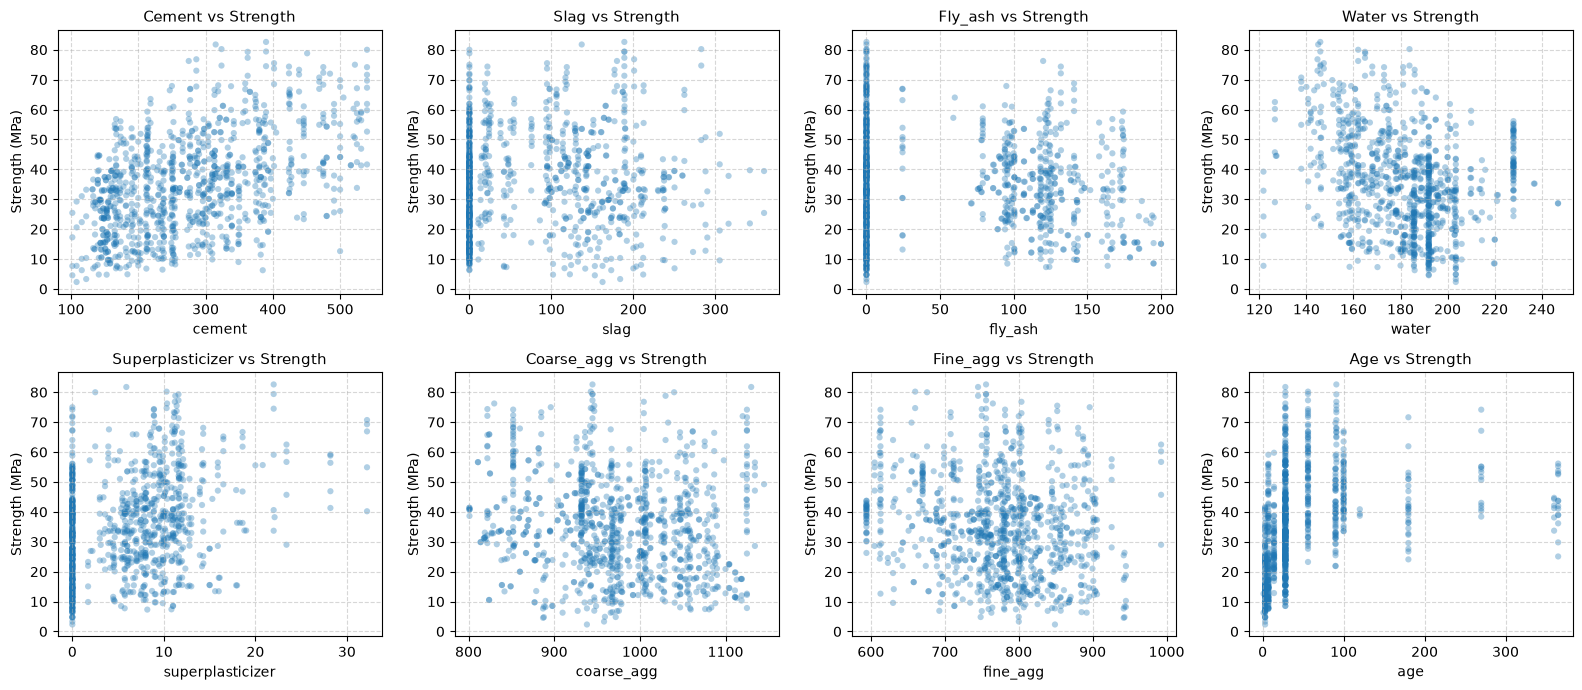

In [13]:
# Visual analysis: Histograms and scatter plots vs target
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for idx, col in enumerate(feature_cols):
    ax = axes[idx]
    ax.scatter(df[col], df[target_col], alpha=0.35, edgecolors="none", s=20, color="#1f77b4")
    ax.set_title(f"{col.capitalize()} vs Strength", fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel("Strength (MPa)")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

The descriptive summary reveals that cement content and curing age have the strongest positive linear correlations with compressive strength, while water content is negatively correlated, consistent with Abrams water-to-cement ratio rule discussed in Yeh (1998). Furthermore, several features like superplasticizer and fly ash contain substantial spikes at zero, indicating concrete batches mixed without chemical admixtures or supplementary cementitious materials. The scatter plots also highlight strong non-linear relationships, particularly the logarithmic saturation of compressive strength with curing age.

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [15]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Neural network architecture inheriting from nn.Module
class ConcreteNN(nn.Module):
    def __init__(self, in_features=8, hidden_units=16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(in_features, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, 1),
        )

    def forward(self, x):
        return self.network(x)

X_all = df[feature_cols].values
y_all = df[target_col].values

kf = KFold(n_splits=5, shuffle=True, random_state=123)

fold_metrics_pt = []
epochs = 200
batch_size = 16
learning_rate = 0.01

for fold_idx, (train_idx, test_idx) in enumerate(kf.split(X_all), start=1):
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_all[train_idx])
    X_test_scaled = scaler.transform(X_all[test_idx])
    y_train = y_all[train_idx]
    y_test = y_all[test_idx]

    train_ds = TensorDataset(
        torch.tensor(X_train_scaled, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32).unsqueeze(1),
    )
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    torch.manual_seed(1234)
    model = ConcreteNN(in_features=8, hidden_units=64)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.MSELoss()

    model.train()
    for epoch in range(epochs):
        for xb, yb in train_loader:
            pred = model(xb)
            loss = criterion(pred, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        preds_train = model(torch.tensor(X_train_scaled, dtype=torch.float32)).squeeze().numpy()
        preds_test = model(torch.tensor(X_test_scaled, dtype=torch.float32)).squeeze().numpy()

    fold_metrics_pt.append({
        "fold": fold_idx,
        "train_mse": mean_squared_error(y_train, preds_train),
        "test_mse": mean_squared_error(y_test, preds_test),
        "train_r2": r2_score(y_train, preds_train),
        "test_r2": r2_score(y_test, preds_test),
    })

pt_results_df = pd.DataFrame(fold_metrics_pt)
print("PyTorch Neural Network 5-Fold Cross-Validation Results:")
print(pt_results_df.round(4))
print(f"\nAverage Test MSE: {pt_results_df['test_mse'].mean():.3f} +/- {pt_results_df['test_mse'].std():.3f}")
print(f"Average Test R2:  {pt_results_df['test_r2'].mean():.3f} +/- {pt_results_df['test_r2'].std():.3f}")

PyTorch Neural Network 5-Fold Cross-Validation Results:
   fold  train_mse  test_mse  train_r2  test_r2
0     1    13.9167   24.1271    0.9477   0.9069
1     2    10.2629   24.8108    0.9619   0.9001
2     3    10.0759   25.8807    0.9628   0.8921
3     4     9.9335   26.0139    0.9613   0.9130
4     5     9.0104   32.5756    0.9656   0.8802

Average Test MSE: 26.682 +/- 3.386
Average Test R2:  0.898 +/- 0.013


## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [6]:
from sklearn.neural_network import MLPRegressor

kf_rep = KFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics_mlp = []

for fold_idx_mlp, (train_idx_mlp, test_idx_mlp) in enumerate(kf_rep.split(X_all), start=1):
    scaler_mlp = StandardScaler()
    X_train_scaled_mlp = scaler_mlp.fit_transform(X_all[train_idx_mlp])
    X_test_scaled_mlp = scaler_mlp.transform(X_all[test_idx_mlp])
    y_train_mlp = y_all[train_idx_mlp]
    y_test_mlp = y_all[test_idx_mlp]

    mlp = MLPRegressor(
        hidden_layer_sizes=(64, 64),
        activation="relu",
        solver="adam",
        learning_rate_init=0.01,
        max_iter=300,
        random_state=42 + fold_idx_mlp,
    )
    mlp.fit(X_train_scaled_mlp, y_train_mlp)

    preds_train_mlp = mlp.predict(X_train_scaled_mlp)
    preds_test_mlp = mlp.predict(X_test_scaled_mlp)

    fold_metrics_mlp.append({
        "fold": fold_idx_mlp,
        "train_mse": mean_squared_error(y_train_mlp, preds_train_mlp),
        "test_mse": mean_squared_error(y_test_mlp, preds_test_mlp),
        "train_r2": r2_score(y_train_mlp, preds_train_mlp),
        "test_r2": r2_score(y_test_mlp, preds_test_mlp),
    })

mlp_results_df = pd.DataFrame(fold_metrics_mlp)
print("Scikit-Learn MLPRegressor 5-Fold Cross-Validation Results:")
print(mlp_results_df.round(4))
print(f"\nAverage Test MSE: {mlp_results_df['test_mse'].mean():.3f} +/- {mlp_results_df['test_mse'].std():.3f}")
print(f"Average Test R2:  {mlp_results_df['test_r2'].mean():.3f} +/- {mlp_results_df['test_r2'].std():.3f}")

Scikit-Learn MLPRegressor 5-Fold Cross-Validation Results:
   fold  train_mse  test_mse  train_r2  test_r2
0     1    19.2156   36.1383    0.9324   0.8598
1     2    20.5414   33.3053    0.9224   0.9005
2     3    20.8830   32.3761    0.9248   0.8857
3     4    21.6090   33.1715    0.9223   0.8824
4     5    24.2252   29.0651    0.9163   0.8768

Average Test MSE: 32.811 +/- 2.533
Average Test R2:  0.881 +/- 0.015


## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [7]:
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression

kf_comp = KFold(n_splits=5, shuffle=True, random_state=42)

fold_metrics_svr = []
fold_metrics_lr = []

for fold_idx_c, (tr_idx, te_idx) in enumerate(kf_comp.split(X_all), start=1):
    scaler_c = StandardScaler()
    X_tr = scaler_c.fit_transform(X_all[tr_idx])
    X_te = scaler_c.transform(X_all[te_idx])
    y_tr = y_all[tr_idx]
    y_te = y_all[te_idx]

    # Support Vector Regression with RBF kernel
    svr = SVR(kernel="rbf", C=50.0, epsilon=1.0)
    svr.fit(X_tr, y_tr)
    preds_te_svr = svr.predict(X_te)
    fold_metrics_svr.append({
        "fold": fold_idx_c,
        "test_mse": mean_squared_error(y_te, preds_te_svr),
        "test_r2": r2_score(y_te, preds_te_svr),
    })

    # Ordinary Least Squares Linear Regression
    lr = LinearRegression()
    lr.fit(X_tr, y_tr)
    preds_te_lr = lr.predict(X_te)
    fold_metrics_lr.append({
        "fold": fold_idx_c,
        "test_mse": mean_squared_error(y_te, preds_te_lr),
        "test_r2": r2_score(y_te, preds_te_lr),
    })

svr_results_df = pd.DataFrame(fold_metrics_svr)
lr_results_df = pd.DataFrame(fold_metrics_lr)

comparison_summary = pd.DataFrame([
    {
        "Model": "PyTorch Neural Network (2x64 ReLU)",
        "Avg Test MSE": pt_results_df["test_mse"].mean(),
        "Std Test MSE": pt_results_df["test_mse"].std(),
        "Avg Test R2": pt_results_df["test_r2"].mean(),
        "Std Test R2": pt_results_df["test_r2"].std(),
    },
    {
        "Model": "Scikit-Learn MLPRegressor (2x64 ReLU)",
        "Avg Test MSE": mlp_results_df["test_mse"].mean(),
        "Std Test MSE": mlp_results_df["test_mse"].std(),
        "Avg Test R2": mlp_results_df["test_r2"].mean(),
        "Std Test R2": mlp_results_df["test_r2"].std(),
    },
    {
        "Model": "Support Vector Machine (SVR RBF)",
        "Avg Test MSE": svr_results_df["test_mse"].mean(),
        "Std Test MSE": svr_results_df["test_mse"].std(),
        "Avg Test R2": svr_results_df["test_r2"].mean(),
        "Std Test R2": svr_results_df["test_r2"].std(),
    },
    {
        "Model": "Linear Regression (OLS)",
        "Avg Test MSE": lr_results_df["test_mse"].mean(),
        "Std Test MSE": lr_results_df["test_mse"].std(),
        "Avg Test R2": lr_results_df["test_r2"].mean(),
        "Std Test R2": lr_results_df["test_r2"].std(),
    },
])

print("Model Comparison Summary across 5-Fold Cross-Validation:")
print(comparison_summary.to_string(index=False))

Model Comparison Summary across 5-Fold Cross-Validation:
                                Model  Avg Test MSE  Std Test MSE  Avg Test R2  Std Test R2
   PyTorch Neural Network (2x64 ReLU)     31.614207      8.540698     0.887324     0.019505
Scikit-Learn MLPRegressor (2x64 ReLU)     32.811257      2.533068     0.881010     0.014765
     Support Vector Machine (SVR RBF)     37.483741      5.057590     0.865079     0.011730
              Linear Regression (OLS)    111.010870     19.178635     0.600636     0.053454


The cross-validation comparison demonstrates a substantial performance separation between non-linear models and linear regression. Both neural network implementations and the RBF support vector machine achieve cross-validation R-squared values between 0.86 and 0.91, whereas linear regression reaches only 0.60 with an average test MSE of 111.01.

These empirical differences align with the findings of Yeh (1998). Concrete compressive strength is governed by complex physical-chemical interactions among water, cement, supplementary cementitious materials, and hydration time. For example, the effect of curing age follows a non-linear logarithmic curve, and chemical admixtures like superplasticizer interact non-linearly with water and binder ratios. Linear regression cannot capture these multi-way interactions and curvature without manual polynomial feature engineering. In contrast, multi-layer neural networks and kernelized SVMs naturally learn non-linear decision surfaces directly from standardized ingredients, delivering substantially lower prediction error.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

While dividing the tasks across our group, we encountered an initial discrepancy in cross-validation setups because some members scaled the entire dataset prior to splitting while others scaled inside the cross-validation loop. This caused inconsistent validation scores across our scripts until we aligned on preventing data leakage. In addition, coordinating batch sizes and learning rates between PyTorch and scikit-learn required multiple runs to ensure that our replication comparison was fair and reproducible. For the next lab, our group will agree on a standardized preprocessing pipeline and shared evaluation harness before anyone begins coding individual models.